In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.testing import print_coercion_tables
from skimage.filters.rank import gradient

Przykład 1

In [2]:
W = np.array([
    [0.1,0.1,-0.3],
    [0.1,0.2,0.0],
    [0.0,0.7,0.1],
    [0.2,0.4,0.0],
    [-0.3,0.5,0.1]
])

x = np.array([
    [0.5],
    [0.75],
    [0.1]
])

y = np.array([
    [0.1],
    [1],
    [0.1],
    [0.0],
    [-0.1]
])

alpha = 0.01

output = np.dot(W,x)
error = np.subtract(output, y)
gradient = np.multiply(error, 2/W.shape[0])
delta = np.outer(gradient,x)

W = W - np.multiply(alpha, delta)

W

array([[ 1.00010e-01,  1.00015e-01, -2.99998e-01],
       [ 1.01600e-01,  2.02400e-01,  3.20000e-04],
       [-8.70000e-04,  6.98695e-01,  9.98260e-02],
       [ 1.99200e-01,  3.98800e-01, -1.60000e-04],
       [-3.00670e-01,  4.98995e-01,  9.98660e-02]])

 Epoch   5 | 0.8000128000   | -0.0000128000
 Epoch  20 | 0.8000000000   | -0.0000000000
 Epoch  30 | 0.8000000000   | 0.0000000000
 Epoch  50 | 0.8000000000   | 0.0000000000


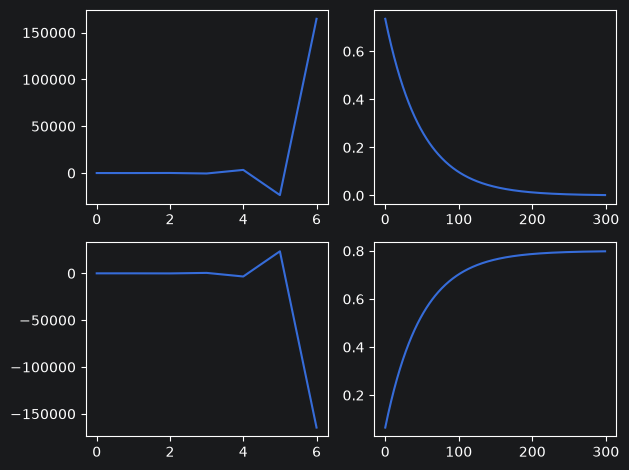

In [3]:
#zadanie 1
WEntry = 0.5
YExpected = 0.8
Input = 2
alpha = 0.1

class Neuron:
    def __init__(self, w):
        self.weight = w

    def output(self, input_value):
        return self.weight * input_value

    def error(self, input_value, expected_output):
        return expected_output - self.weight * input_value


    def train(self, input_value, expected_val, alpha):
        output_value = self.weight * input_value
        error = (output_value - expected_val)
        delta = error * 2 * input_value
        self.weight = self.weight - alpha * delta

neuron = Neuron(WEntry)
neuronTest1 = Neuron(WEntry)
neuronTest2 = Neuron(WEntry)
epochs = [5,20,30,50]

for i in range(max(epochs)+1):
    neuron.train(Input,YExpected,alpha)
    if i in epochs:
        print(f' Epoch {i:3d} | {neuron.output(Input):.10f}   | {neuron.error(Input, YExpected):.10f}')



neuronTest1 = Neuron(WEntry)
neuronTest2 = Neuron(WEntry)

errorTest1 = []
errorTest2 = []
valueTest1 = []
valueTest2 = []



for i in range(300):
    neuronTest1.train(2, YExpected, 1)

    neuronTest2.train(0.1, YExpected, 1)

    out1 = neuronTest1.output(2)
    err1 = neuronTest1.error(2, YExpected)

    out2 = neuronTest2.output(0.1)
    err2 = neuronTest2.error(0.1, YExpected)
    errorTest1.append(err1)
    errorTest2.append(err2)
    valueTest1.append(out1)
    valueTest2.append(out2)


x = np.arange(0,300)

fig,ax = plt.subplots(2,2)

ax[0,0].plot(x[0:7],errorTest1[0:7])
ax[0,1].plot(x,errorTest2)
ax[1,0].plot(x[0:7],valueTest1[0:7])
ax[1,1].plot(x,valueTest2)
plt.tight_layout()
plt.show()


In [7]:
#zadanie 2

W = np.array([
     [0.1,0.1,-0.3],
     [0.1,0.2,0.0],
     [0.0,0.7,0.1],
     [0.2,0.4,0.0],
     [-0.3,0.5,0.1]])


x = np.array([[0.5,0.1,0.2,0.8],
             [0.75,0.3,0.1,0.9],
             [0.1,0.7,0.6,0.2]])

y = np.array([[0.1,0.5,0.1,0.7],
     [1.0,0.2,0.3,0.6],
     [0.1,-0.5,0.2,0.2],
     [0.0,0.3,0.9,-0.1],
     [-0.1,0.7,0.1,0.8]])

alpha = 0.01



class Dense_Neural_Network:

    def __init__(self, input_dim:int):
        self.weights_list:list[np.ndarray] = list()
        self.input_dim:int = input_dim


    def add_layer(self, n, weight_min_value=None, weight_max_value = None, weights :np.ndarray = None):
        if weights is None:
            weights = np.random.uniform(weight_min_value, weight_max_value, (n, self.input_dim))
        if(weights.shape[0] != n):
            print("weights row number and weights column number must be equal")
            return
        self.weights_list.append(weights)
        self.input_dim = n

    def predict(self, inputs) -> np.ndarray:
        if inputs.shape[0] != self.weights_list[0].shape[1]:
            print("inputs row number and weights column number must be equal")
            return
        out = np.dot(self.weights_list[0], inputs)
        for i in range(len(self.weights_list) - 1):
            if out.shape[0] != self.weights_list[i + 1].shape[1]:
                print("inputs row number and weights column number must be equal")
                return
            out = np.dot(self.weights_list[i + 1], out)
        return out

    def get_loss(self, input, expected_output)->float:
        return np.sum(np.power(np.subtract(self.predict(input), expected_output),2))

    def load_weights(self, file_name):
        fp:np.ndarray = np.load(file_name)
        self.add_layer(fp.shape[0],None,None,fp)

    def train_last_layer(self,input, expected_output, alpha):
        out = self.predict(input)
        error  = np.subtract(out, expected_output)
        gradient = np.multiply(error, 2 / self.weights_list[-1].shape[0])
        delta = np.outer(gradient,input)
        desire_subt = np.multiply(alpha,delta)
        self.weights_list[0] = np.subtract(self.weights_list[0], desire_subt)

model = Dense_Neural_Network(3)
model.add_layer(5,None,None,W)

print(x)
print(y)
print(model.weights_list[0])


epoch_number = 1000
debug = False
for _ in range(epoch_number):
    epoch_error = 0
    for i in range(4):
        epoch_error += model.get_loss(x[:, i], y[:, i])
        model.train_last_layer(x[:, i], y[:, i], alpha)
    print(f"Epoch : {_} | Error: {np.divide(epoch_error,5)}")


[[0.5  0.1  0.2  0.8 ]
 [0.75 0.3  0.1  0.9 ]
 [0.1  0.7  0.6  0.2 ]]
[[ 0.1  0.5  0.1  0.7]
 [ 1.   0.2  0.3  0.6]
 [ 0.1 -0.5  0.2  0.2]
 [ 0.   0.3  0.9 -0.1]
 [-0.1  0.7  0.1  0.8]]
[[ 0.1  0.1 -0.3]
 [ 0.1  0.2  0. ]
 [ 0.   0.7  0.1]
 [ 0.2  0.4  0. ]
 [-0.3  0.5  0.1]]
Epoch : 0 | Error: 0.927550687308982
Epoch : 1 | Error: 0.917508224079748
Epoch : 2 | Error: 0.9076563896134054
Epoch : 3 | Error: 0.8979912988649501
Epoch : 4 | Error: 0.8885091474473471
Epoch : 5 | Error: 0.8792062099491161
Epoch : 6 | Error: 0.8700788382870497
Epoch : 7 | Error: 0.8611234600933351
Epoch : 8 | Error: 0.8523365771363526
Epoch : 9 | Error: 0.8437147637744553
Epoch : 10 | Error: 0.8352546654420372
Epoch : 11 | Error: 0.8269529971672144
Epoch : 12 | Error: 0.8188065421204627
Epoch : 13 | Error: 0.8108121501935603
Epoch : 14 | Error: 0.8029667366082072
Epoch : 15 | Error: 0.7952672805536967
Epoch : 16 | Error: 0.787710823853037
Epoch : 17 | Error: 0.7802944696569252
Epoch : 18 | Error: 0.773015381164

In [5]:
    #zadanie 3 trenowanie modelu kolorów
import numpy as np

color_inputs = []
expected_colors_output = []

with open("data/colors_train.txt", "r", encoding="utf-8") as file:
    for line in file:
        parsed_line = line.split()

        if len(parsed_line) >= 4:
            color_inputs.append([float(x) for x in parsed_line[0:3]])
            temp = [0,0,0,0]
            temp[int(parsed_line[3])-1] = 1
            expected_colors_output.append(temp)

    color_inputs = np.array(color_inputs).T
    expected_colors_output = np.array(expected_colors_output).T

colors_model = Dense_Neural_Network(3)
colors_model.add_layer(4,0.01,0.99)

print("Kształt inputs:", color_inputs.shape)
print(color_inputs[:,:10])
print("\nKształt expected_outputs:", expected_colors_output.shape)
print(expected_colors_output[:,0:10])



epoch_number = 1000
debug = False
for _ in range(epoch_number):
    epoch_error = 0
    for i in range(expected_colors_output.shape[1]):
        epoch_error += colors_model.get_loss(color_inputs[:, i], expected_colors_output[:, i])
        colors_model.train_last_layer(color_inputs[:, i], expected_colors_output[:, i], alpha)
    print(f"Epoch : {_} | Error: {np.divide(epoch_error,4)}")


Kształt inputs: (3, 109)
[[0.91 0.91 0.89 0.82 0.19 0.2  0.1  0.22 0.2  0.03]
 [0.82 0.09 0.9  0.04 0.91 0.17 0.97 0.97 0.2  0.97]
 [0.05 0.26 0.18 0.08 0.   0.9  0.   0.03 0.89 0.21]]

Kształt expected_outputs: (4, 109)
[[0 1 0 1 0 0 0 0 0 0]
 [0 0 0 0 1 0 1 1 0 1]
 [0 0 0 0 0 1 0 0 1 0]
 [1 0 1 0 0 0 0 0 0 0]]
Epoch : 0 | Error: 45.274167200992
Epoch : 1 | Error: 30.64209961732081
Epoch : 2 | Error: 23.1239701579534
Epoch : 3 | Error: 18.93383581945716
Epoch : 4 | Error: 16.35989245619559
Epoch : 5 | Error: 14.61825272982526
Epoch : 6 | Error: 13.341776521261554
Epoch : 7 | Error: 12.351842598312356
Epoch : 8 | Error: 11.556226916768807
Epoch : 9 | Error: 10.903223545295974
Epoch : 10 | Error: 10.360879971061928
Epoch : 11 | Error: 9.90747222908767
Epoch : 12 | Error: 9.527031379169467
Epoch : 13 | Error: 9.20715756306502
Epoch : 14 | Error: 8.937884440913033
Epoch : 15 | Error: 8.71103776972289
Epoch : 16 | Error: 8.51983605438509
Epoch : 17 | Error: 8.358617399187404
Epoch : 18 | E

In [14]:
#zadanie 3
#sprawdzenie testowego modelu

color_inputs = []
expected_colors_output = []

with open("data/colors_test.txt", "r", encoding="utf-8") as file:
    for line in file:
        parsed_line = line.split()

        if len(parsed_line) >= 4:
            color_inputs.append([float(x) for x in parsed_line[0:3]])
            temp = [0,0,0,0]
            temp[int(parsed_line[3])-1] = 1
            expected_colors_output.append(temp)

    color_inputs = np.array(color_inputs).T
    expected_colors_output = np.array(expected_colors_output).T


total_error = 0
okejki = 0
for i in range(expected_colors_output.shape[1]):
    total_error += colors_model.get_loss(color_inputs[:, i], expected_colors_output[:, i])
    max_index =np.argmax(colors_model.predict(color_inputs[:, i]))
    if expected_colors_output[max_index,i] ==0:
        pass
        #print("błędne przewidywanie")
    else:
        #print("poprawne przewidywanie")
        okejki+=1

print(f" Error zbioru testowego: {np.divide(epoch_error,4)} | Zgodność {okejki/expected_colors_output.shape[1] * 100} %")



 Error zbioru testowego: 0.32277243891793317 | Zgodność 100.0 %
